<a href="https://colab.research.google.com/github/YoliyanaKeb/Data201-labs/blob/main/Data%20201-Project1/Data_201_project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Breast Cancer

PART 1: UNDERSTANDING THE PROBLEM

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
brca= pd.read_csv("/content/drive/My Drive/Colab Notebooks/Data_201/Datasets/brca.csv")
brca.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


Each of the rows in this dataset represents one breast observation with diffrent types of measurments.The response variable is y becuase its two classes are the two types of diagnosis.

In [3]:
brca.shape

(569, 32)

This dataset contains 569 observations and 32 columns.
Diagnosis (M = malignant, B = benign)

In [4]:
brca.keys()

Index(['Unnamed: 0', 'x.radius_mean', 'x.texture_mean', 'x.perimeter_mean',
       'x.area_mean', 'x.smoothness_mean', 'x.compactness_mean',
       'x.concavity_mean', 'x.concave_pts_mean', 'x.symmetry_mean',
       'x.fractal_dim_mean', 'x.radius_se', 'x.texture_se', 'x.perimeter_se',
       'x.area_se', 'x.smoothness_se', 'x.compactness_se', 'x.concavity_se',
       'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se',
       'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst',
       'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst',
       'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst',
       'x.fractal_dim_worst', 'y'],
      dtype='object')

In [5]:
brca.describe()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,569.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [6]:
brca["y"].value_counts()

,count
y,
B,357
M,212


This dataset is not fully balanced becuase it shows that it has 357 benign and 212 malignants.

In [7]:
brca.isna().sum()

,0
Unnamed: 0,0
x.radius_mean,0
x.texture_mean,0
x.perimeter_mean,0
x.area_mean,0
x.smoothness_mean,0
x.compactness_mean,0
x.concavity_mean,0
x.concave_pts_mean,0
x.symmetry_mean,0


There are no missing values in this dataset so we can now continue to work with it.

In [8]:
# set your features and target
X = brca[["x.radius_mean", "x.texture_mean", "x.perimeter_mean"]]

y = brca["y"]

In this case a FP is when the model pridicts malignant when it is benign instead. A FN is when the model preidcts benign instead of malignant. I would be more concerned about the false negative becuase someone who has cancer might not get the needed treatment.

The  features and predictors used
are
- x.radius_mean
- x.texture_mean
- x.perimeter_mean

In [9]:
brca[["x.radius_mean", "x.texture_mean", "x.perimeter_mean"]].describe()

,x.radius_mean,x.texture_mean,x.perimeter_mean
count,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033
std,3.524049,4.301036,24.298981
min,6.981000,9.710000,43.790000
25%,11.700000,16.170000,75.170000
50%,13.370000,18.840000,86.240000
75%,15.780000,21.800000,104.100000
max,28.110000,39.280000,188.500000


Encoding the target varibale

In [10]:
#Convert the target variable into numeric form
brca["y_num"] = brca["y"].map({
    "B": 0,
    "M": 1
})

In [11]:
# define features and target
X = brca[["x.radius_mean", "x.texture_mean", "x.perimeter_mean"]]
y = brca["y_num"]

Now we will divide the data

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.25,
random_state=0)


Next didvide thr dataste into 75% traning and 25% testing. Using the K-fold CV on the training dataset

In [13]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

#Create model
lda = LinearDiscriminantAnalysis()
from sklearn.model_selection import cross_val_score

lda_cv = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=5
)

lda_cv

array([0.90697674, 0.88235294, 0.91764706, 0.87058824, 0.88235294])

The results show how the model performed across the k- folds

I  think the predictors should be standardized because their values are different.

3A: For Logistic Regression

In [14]:

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

logreg.fit(X_train, y_train)
#Make prediction
logreg_pred = logreg.predict(X_test)

In [15]:
# Now compare your calculation with scikit-learn
logreg.predict_proba(X_test)

array([[1.11652368e-02, 9.88834763e-01],
       [4.62852188e-01, 5.37147812e-01],
       [9.08807601e-01, 9.11923988e-02],
       [9.31981680e-01, 6.80183204e-02],
       [9.92147505e-01, 7.85249540e-03],
       [3.69204858e-02, 9.63079514e-01],
       [3.89583310e-02, 9.61041669e-01],
       [9.88454346e-01, 1.15456544e-02],
       [2.77696086e-02, 9.72230391e-01],
       [9.65777606e-01, 3.42223936e-02],
       [4.99803983e-01, 5.00196017e-01],
       [9.86066445e-01, 1.39335550e-02],
       [3.28690601e-06, 9.99996713e-01],
       [9.32513237e-01, 6.74867632e-02],
       [9.98346772e-01, 1.65322796e-03],
       [9.75308396e-01, 2.46916035e-02],
       [9.98763407e-01, 1.23659252e-03],
       [8.80446367e-01, 1.19553633e-01],
       [5.49284412e-02, 9.45071559e-01],
       [9.82817384e-01, 1.71826165e-02],
       [8.88064775e-01, 1.11935225e-01],
       [7.82644055e-01, 2.17355945e-01],
       [2.82548419e-03, 9.97174516e-01],
       [9.92372002e-01, 7.62799848e-03],
       [6.909555

For this part I used logisitc regression to predict. I trained the model using the training data.

3B: For LDA

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

#Create model
lda = LinearDiscriminantAnalysis()

#Fit the model
lda.fit(X_train, y_train)

#Make prediction
lda_pred = lda.predict(X_test)

3C:For QDA

In [17]:
#QDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

#Create model
qda = QuadraticDiscriminantAnalysis()

#Fit the model
qda.fit(X_train, y_train)

#Make prediction
qda_pred = qda.predict(X_test)
qda_pred

array([1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0])

3D:For KNN

In [18]:
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import make_pipeline
#Test these possible values
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5
    )

    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.8685088919288646), np.float64(0.8803009575923392), np.float64(0.8755403556771546), np.float64(0.8638850889192886), np.float64(0.8732421340629275), np.float64(0.8803009575923392), np.float64(0.8873324213406292), np.float64(0.8873050615595075)]


[np.float64(0.8685088919288646), np.float64(0.8803009575923392), np.float64(0.8755403556771546), np.float64(0.8638850889192886), np.float64(0.8732421340629275), np.float64(0.8803009575923392), np.float64(0.8873324213406292), np.float64(0.8873050615595075)]
- based on this np.float64(0.8873324213406292) is slightly higher than the other o we pick k=15 becuase the highest vlaue is found on the 15 k-value.

In [19]:
from sklearn.metrics import (accuracy_score)
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

#fit
best_knn.fit(X_train, y_train)

#predict
best_knn_pred = best_knn.predict(X_test)

#evaluate
accuracy_score(y_test, best_knn_pred)

0.9370629370629371

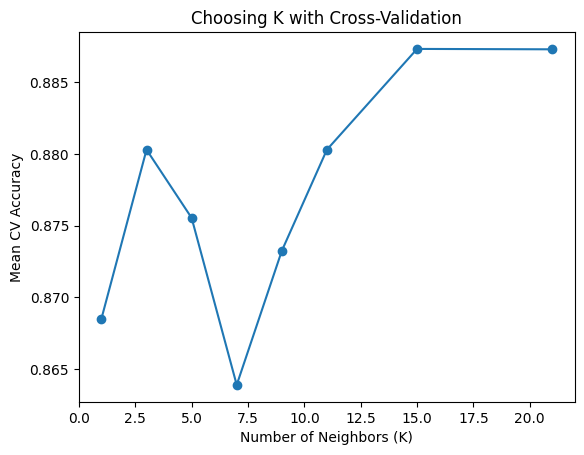

In [20]:
import matplotlib.pyplot as plt
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

This graph shows that the highest accuracy was k-15 at 88.7%.

PART 4: EVALUATING MODELS

In [21]:
#LDA
#Fit the final model using all training data
lda.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
lda.classes_

#get the probability of defaulting "Yes"
prob_m = lda.predict_proba(X_test)[:, 1]

prob_m[:10]

array([0.94643236, 0.41146408, 0.10642675, 0.04228533, 0.00977696,
       0.94437018, 0.92709175, 0.01102087, 0.89146003, 0.02864854])

In [22]:
import numpy as np

#Threshold = 50%
pred_50 = np.where(
    prob_m>= 0.50,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_50,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[86  1]
 [12 44]]
TN: 86
FP: 1
FN: 12
TP: 44


Lets check if changing thresholds affect our results

In [23]:
#Threshold = 30%
pred_30 = np.where(
    prob_m>= 0.30,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

TN30, FP30, FN30, TP30 = cm30.ravel()

print("TN:", TN30)
print("FP:", FP30)
print("FN:", FN30)
print("TP:", TP30)

[[85  2]
 [ 4 52]]
TN: 85
FP: 2
FN: 4
TP: 52


so from changing the threshold from 50 to 30 it compartively missed less malignants so i think the lower is better for this problem becuase as we said eariler not catching the malignant tumor is bad.

In [24]:
from sklearn.metrics import (
     accuracy_score,
     precision_score,
     recall_score,
    f1_score)
accuracy = accuracy_score(
    y_test,
    pred_50)
precision = precision_score(
    y_test,
    pred_50,
    pos_label=1)
recall = recall_score(
    y_test,
    pred_50,
    pos_label=1)
specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_50,
    pos_label=1
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.9090909090909091
Precision: 0.9777777777777777
Recall: 0.7857142857142857
Specificity: 0.9885057471264368
F1: 0.8712871287128713


In [25]:

accuracy30 = accuracy_score(
    y_test,
    pred_30)
precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1)
recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1)
specificity30 = TN30 / (TN30 + FP30)

f130 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f130)

Accuracy: 0.958041958041958
Precision: 0.9629629629629629
Recall: 0.9285714285714286
Specificity: 0.9770114942528736
F1: 0.9454545454545454


For the LDA model i would choose the 30% threshold becuase it important to not miss the malignant.

In [26]:
from sklearn.metrics import (roc_auc_score)
auc_lda = roc_auc_score(
    y_test,
    prob_m
)

print("LDA AUC:", auc_lda)

LDA AUC: 0.986863711001642


In [27]:
#Logisitc regression
#Fit the final model using all training data
logreg.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
logreg.classes_

#get the probability of defaulting "Yes"
prob_m_logreg = logreg.predict_proba(X_test)[:, 1]

prob_m_logreg[:10]

array([0.98883476, 0.53714781, 0.0911924 , 0.06801832, 0.0078525 ,
       0.96307951, 0.96104167, 0.01154565, 0.97223039, 0.03422239])

In [28]:
#Threshold = 50%
logreg_pred_50 = np.where(
   prob_m_logreg>= 0.50,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmlogreg50 = confusion_matrix(
    y_test,
    logreg_pred_50,
    labels=[0, 1]
)

print(cmlogreg50)

TN_log50, FP_log50, FN_log50, TP_log50 = cmlogreg50.ravel()

print("TN:", TN_log50)
print("FP:", FP_log50)
print("FN:", FN_log50)
print("TP:", TP_log50)

[[85  2]
 [ 4 52]]
TN: 85
FP: 2
FN: 4
TP: 52


In [29]:
#Threshold = 30%
logreg_pred_30 = np.where(
   prob_m_logreg>= 0.30,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmlogreg30 = confusion_matrix(
    y_test,
    logreg_pred_30,
    labels=[0, 1]
)

print(cmlogreg30)

TN_log30, FP_log30, FN_log30, TP_log30 = cmlogreg30.ravel()

print("TN:", TN_log30)
print("FP:", FP_log30)
print("FN:", FN_log30)
print("TP:", TP_log30)

[[81  6]
 [ 3 53]]
TN: 81
FP: 6
FN: 3
TP: 53


In [30]:
accuracy_log50 = accuracy_score(
    y_test,
    logreg_pred_50)
precision_log50 = precision_score(
    y_test,
    logreg_pred_50,
    pos_label=1)
recall_log50 = recall_score(
    y_test,
    logreg_pred_50,
    pos_label=1)
specificity_log50 = TN_log50 / (TN_log50 + FP_log50)

f1_log50 = f1_score(
    y_test,
    logreg_pred_50,
    pos_label=1
)

print("Accuracy:", accuracy_log50)
print("Precision:", precision_log50)
print("Recall:", recall_log50)
print("Specificity:", specificity_log50)
print("F1:", f1_log50)

Accuracy: 0.958041958041958
Precision: 0.9629629629629629
Recall: 0.9285714285714286
Specificity: 0.9770114942528736
F1: 0.9454545454545454


In [31]:
accuracy_log30 = accuracy_score(
    y_test,
    logreg_pred_30)
precision_log30 = precision_score(
    y_test,
    logreg_pred_30,
    pos_label=1)
recall_log30 = recall_score(
    y_test,
    logreg_pred_30,
    pos_label=1)
specificity_log30 = TN_log30 / (TN_log30 + FP_log30)

f1_log30 = f1_score(
    y_test,
    logreg_pred_30,
    pos_label=1
)

print("Accuracy:", accuracy_log30)
print("Precision:", precision_log30)
print("Recall:", recall_log30)
print("Specificity:", specificity_log30)
print("F1:", f1_log30)

Accuracy: 0.9370629370629371
Precision: 0.8983050847457628
Recall: 0.9464285714285714
Specificity: 0.9310344827586207
F1: 0.9217391304347826


For logisitc regression the 50% threshold had better accuracy, precision, specificty and F1 score. But 30% threshold still found more malignants so that is the better becuase we have to aviod missing that.

In [32]:

auc_logreg = roc_auc_score(
    y_test,
    prob_m_logreg
)

print("logisitic regresion AUC:", auc_logreg)


logisitic regresion AUC: 0.9802955665024631


In [33]:
#QDA
#Fit the final model using all training data
qda.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
qda.classes_

#get the probability of defaulting "Yes"
prob_m_qda= qda.predict_proba(X_test)[:, 1]

prob_m_qda[:10]

array([0.99558384, 0.53704927, 0.6991987 , 0.05705436, 0.03629308,
       0.99999448, 0.99864915, 0.01983387, 0.96455156, 0.04181529])

In [34]:
#Threshold = 50%
qda_pred_50 = np.where(
   prob_m_qda>= 0.50,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmqda50 = confusion_matrix(
    y_test,
    qda_pred_50,
    labels=[0, 1]
)

print(cmqda50)

TN_qda50, FP_qda50, FN_qda50, TP_qda50 = cmqda50.ravel()

print("TN:", TN_qda50)
print("FP:", FP_qda50)
print("FN:", FN_qda50)
print("TP:", TP_qda50)

[[87  0]
 [ 6 50]]
TN: 87
FP: 0
FN: 6
TP: 50


In [35]:
#Threshold = 30%
qda_pred_30 = np.where(
   prob_m_qda>= 0.30,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmqda30 = confusion_matrix(
    y_test,
    qda_pred_30,
    labels=[0, 1]
)

print(cmqda30)

TN_qda30, FP_qda30, FN_qda30, TP_qda30 = cmqda30.ravel()

print("TN:", TN_qda30)
print("FP:", FP_qda30)
print("FN:", FN_qda30)
print("TP:", TP_qda30)

[[84  3]
 [ 3 53]]
TN: 84
FP: 3
FN: 3
TP: 53


In [36]:
accuracy_qda50 = accuracy_score(
    y_test,
    qda_pred_50)
precision_qda50 = precision_score(
    y_test,
    qda_pred_50,
    pos_label=1)
recall_qda50 = recall_score(
    y_test,
    qda_pred_50,
    pos_label=1)
specificity_qda50 = TN_qda50 / (TN_qda50 + FP_qda50)

f1_qda50 = f1_score(
    y_test,
    qda_pred_50,
    pos_label=1
)

print("Accuracy:", accuracy_qda50)
print("Precision:", precision_qda50)
print("Recall:", recall_qda50)
print("Specificity:", specificity_qda50)
print("F1:", f1_qda50)

Accuracy: 0.958041958041958
Precision: 1.0
Recall: 0.8928571428571429
Specificity: 1.0
F1: 0.9433962264150944


In [37]:
accuracy_qda30 = accuracy_score(
    y_test,
    qda_pred_30)
precision_qda30 = precision_score(
    y_test,
    qda_pred_30,
    pos_label=1)
recall_qda30 = recall_score(
    y_test,
    qda_pred_30,
    pos_label=1)
specificity_qda30 = TN_qda30 / (TN_qda30 + FP_qda30)

f1_qda30 = f1_score(
    y_test,
    qda_pred_30,
    pos_label=1
)

print("Accuracy:", accuracy_qda30)
print("Precision:", precision_qda30)
print("Recall:", recall_qda30)
print("Specificity:", specificity_qda30)
print("F1:", f1_qda30)

Accuracy: 0.958041958041958
Precision: 0.9464285714285714
Recall: 0.9464285714285714
Specificity: 0.9655172413793104
F1: 0.9464285714285714


Both thresholds had the same accuracy. However the 30% threshold had higher recall meaning it found more malignant

In [38]:
auc_qda = roc_auc_score(
    y_test,
    prob_m_qda
)

print("QDA AUC:", auc_qda)

QDA AUC: 0.9954844006568144


In [39]:
#KNN
#Fit the final model using all training data
best_knn.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
best_knn.classes_

#get the probability of defaulting "Yes"
prob_m_knn= best_knn.predict_proba(X_test)[:, 1]

prob_m_knn[:10]

array([1.        , 0.53333333, 0.        , 0.26666667, 0.        ,
       0.86666667, 0.73333333, 0.        , 1.        , 0.06666667])

In [40]:
#Threshold = 50%
knn_pred_50 = np.where(
   prob_m_knn>= 0.50,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmknn50 = confusion_matrix(
    y_test,
    knn_pred_50,
    labels=[0, 1]
)

print(cmknn50)

TN_knn50, FP_knn50, FN_knn50, TP_knn50 = cmknn50.ravel()

print("TN:", TN_knn50)
print("FP:", FP_knn50)
print("FN:", FN_knn50)
print("TP:", TP_knn50)

[[84  3]
 [ 6 50]]
TN: 84
FP: 3
FN: 6
TP: 50


In [41]:
#Threshold = 30%
knn_pred_30 = np.where(
   prob_m_knn>= 0.30,
    1,
    0
)
from sklearn.metrics import (confusion_matrix)
#Confusion Matrix
cmknn30 = confusion_matrix(
    y_test,
    knn_pred_30,
    labels=[0, 1]
)

print(cmknn30)

TN_knn30, FP_knn30, FN_knn30, TP_knn30 = cmknn30.ravel()

print("TN:", TN_knn30)
print("FP:", FP_knn30)
print("FN:", FN_knn30)
print("TP:", TP_knn30)

[[77 10]
 [ 3 53]]
TN: 77
FP: 10
FN: 3
TP: 53


In [42]:
accuracy_knn50 = accuracy_score(
    y_test,
    knn_pred_50)
precision_knn50 = precision_score(
    y_test,
    knn_pred_50,
    pos_label=1)
recall_knn50 = recall_score(
    y_test,
    knn_pred_50,
    pos_label=1)
specificity_knn50 = TN_knn50 / (TN_knn50 + FP_knn50)

f1_knn50 = f1_score(
    y_test,
    knn_pred_50,
    pos_label=1
)

print("Accuracy:", accuracy_knn50)
print("Precision:", precision_knn50)
print("Recall:", recall_knn50)
print("Specificity:", specificity_knn50)
print("F1:", f1_knn50)

Accuracy: 0.9370629370629371
Precision: 0.9433962264150944
Recall: 0.8928571428571429
Specificity: 0.9655172413793104
F1: 0.9174311926605505


In [43]:
accuracy_knn30 = accuracy_score(
    y_test,
    knn_pred_30)
precision_knn30 = precision_score(
    y_test,
    knn_pred_30,
    pos_label=1)
recall_knn30 = recall_score(
    y_test,
    knn_pred_30,
    pos_label=1)
specificity_knn30 = TN_knn30 / (TN_knn30 + FP_knn30)

f1_knn30 = f1_score(
    y_test,
    knn_pred_30,
    pos_label=1
)

print("Accuracy:", accuracy_knn30)
print("Precision:", precision_knn30)
print("Recall:", recall_knn30)
print("Specificity:", specificity_knn30)
print("F1:", f1_knn30)

Accuracy: 0.9090909090909091
Precision: 0.8412698412698413
Recall: 0.9464285714285714
Specificity: 0.8850574712643678
F1: 0.8907563025210085


  The 30% threshold had higher recall and missed only 3 malignant instead of 6.

In [44]:
auc_knn = roc_auc_score(
    y_test,
    prob_m_knn
)

print("KNN AUC:", auc_knn)

KNN AUC: 0.9630541871921182


Reflection:
-  Choosing the right model is important because the results can affect patients. A false negative is when when the model says a tumor is benign when it is actually malignant. This can be dangerous because the patient might not get the treatment they need and will lead to something serious. A false positive happens when the model says a benign tumor is malignant, which means it is still giving us the wrong answer but not be as bad as the first one because you will eventually find out through time. I think false negatives are more serious because missing a malignant can put someone's health at risk. So, I would prefer a model that makes fewer false negative mistakes.

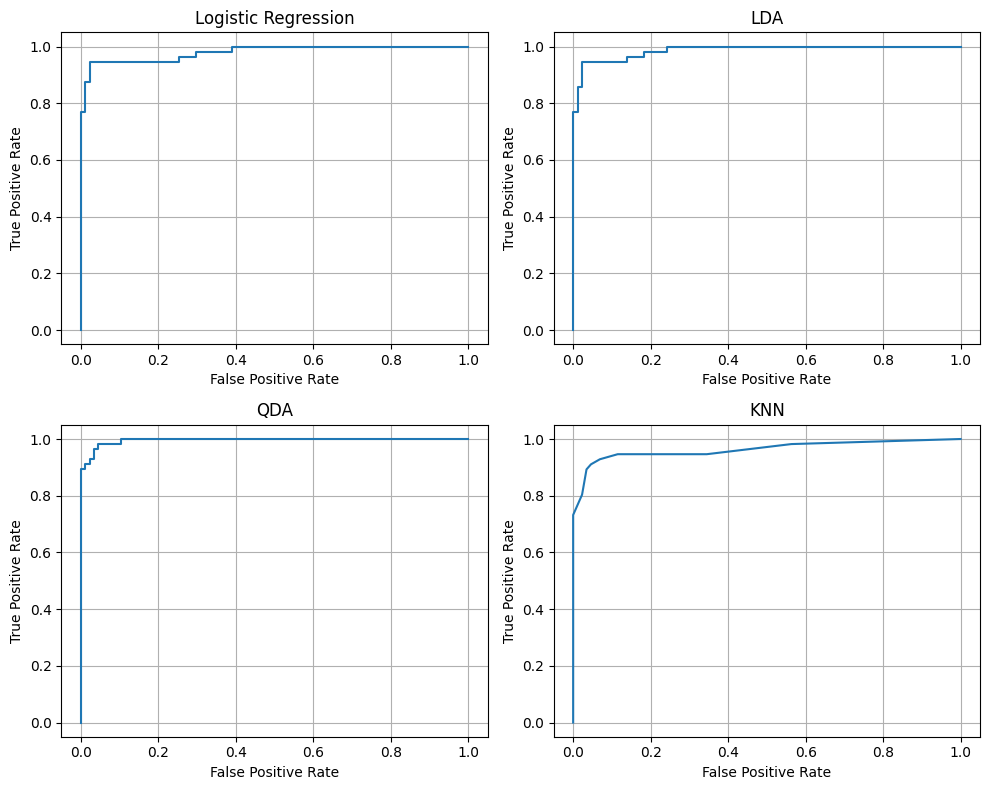

In [45]:
# Used ai for this graph
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ROC curves for all four models
fpr_logreg, tpr_logreg, thresholds_logreg = roc_curve(
    y_test, prob_m_logreg, pos_label=1
)

fpr_lda, tpr_lda, thresholds_lda = roc_curve(
    y_test, prob_m, pos_label=1
)

fpr_qda, tpr_qda, thresholds_qda = roc_curve(
    y_test, prob_m_qda, pos_label=1
)

fpr_knn, tpr_knn, thresholds_knn = roc_curve(
    y_test, prob_m_knn, pos_label=1
)

# Create four graphs
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Logistic Regression
axes[0, 0].plot(fpr_logreg, tpr_logreg)
axes[0, 0].set_title("Logistic Regression")

# LDA
axes[0, 1].plot(fpr_lda, tpr_lda)
axes[0, 1].set_title("LDA")

# QDA
axes[1, 0].plot(fpr_qda, tpr_qda)
axes[1, 0].set_title("QDA")

# KNN
axes[1, 1].plot(fpr_knn, tpr_knn)
axes[1, 1].set_title("KNN")

# Labels for all four graphs
for ax in axes.flat:
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.grid(True)

plt.tight_layout()
plt.show()

QDA performs better than all models.Out of all the classifications QDA had the highest AUC  0.99548 which means that it is the best at separating between the benign and malignant.

Final Analysis:

After comparing the four models I would choose QDA with the 30% threshold as my final model. It had an accuracy of 95.80% and only missed 3 malignants. QDA also had the highest AUC of 0.9955. Checking this things are very important becuase if we miss the malignant can be dangerous can lead to something serious.Compared to KNN QDA missed the same number of malignants but made fewer mistakes overall. One of the limitation of my project is that my dataset has a little bit of imbalance becuase there are 357 benigns and 212 malignants. Overall, I think QDA was the best choice for my project because it performed well compared to the other models.
- this results are important because identifying cancer early is very important and can help reduce the risk it has when it comes to our health.